In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
DATA_DIR = '/content/drive/MyDrive/sen1floods11'
BASE_URL = 'https://storage.googleapis.com/sen1floods11/v1.1'

for sub in ['splits', 'S1Hand', 'LabelHand', 'JRCWaterHand']:
    os.makedirs(os.path.join(DATA_DIR, sub), exist_ok=True)
print(os.listdir(DATA_DIR))

Mounted at /content/drive
['splits', 'S1Hand', 'LabelHand', 'JRCWaterHand']


In [2]:
import urllib.request
import pandas as pd

SPLITS = ['train', 'valid', 'test', 'bolivia']
for s in SPLITS:
    url = f'{BASE_URL}/splits/flood_handlabeled/flood_{s}_data.csv'
    dst = os.path.join(DATA_DIR, 'splits', f'flood_{s}_data.csv')
    urllib.request.urlretrieve(url, dst)

splits = {s: pd.read_csv(os.path.join(DATA_DIR, 'splits', f'flood_{s}_data.csv'),
                         header=None, names=['s1', 'label'])
          for s in SPLITS}
for s, df in splits.items():
    print(f'{s:8s} {len(df):4d} chips')
splits['train'].head()

train     252 chips
valid      89 chips
test       90 chips
bolivia    15 chips


,s1,label
0,Ghana_103272_S1Hand.tif,Ghana_103272_LabelHand.tif
1,Ghana_24858_S1Hand.tif,Ghana_24858_LabelHand.tif
2,Ghana_147015_S1Hand.tif,Ghana_147015_LabelHand.tif
3,Ghana_953791_S1Hand.tif,Ghana_953791_LabelHand.tif
4,Ghana_154838_S1Hand.tif,Ghana_154838_LabelHand.tif


In [3]:
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

# Chip ID = file name without the suffix, e.g. "Ghana_103272"
chip_ids = sorted({f.replace('_S1Hand.tif', '') for df in splits.values() for f in df['s1']})
print(len(chip_ids), 'unique chips')

FOLDERS = ['S1Hand', 'LabelHand', 'JRCWaterHand']
jobs = [(f'{BASE_URL}/data/flood_events/HandLabeled/{f}/{cid}_{f}.tif',
         os.path.join(DATA_DIR, f, f'{cid}_{f}.tif'))
        for cid in chip_ids for f in FOLDERS]

def fetch(job):
    url, dst = job
    if os.path.exists(dst) and os.path.getsize(dst) > 0:
        return 'skipped'              # already downloaded on an earlier run
    tmp = dst + '.part'
    urllib.request.urlretrieve(url, tmp)
    os.replace(tmp, dst)              # rename only once the file is complete
    return 'downloaded'

with ThreadPoolExecutor(max_workers=16) as ex:
    results = list(tqdm(ex.map(fetch, jobs), total=len(jobs)))
print({r: results.count(r) for r in set(results)})

446 unique chips


  0%|          | 0/1338 [00:00<?, ?it/s]

{'downloaded': 1338}


In [4]:
for f in FOLDERS:
    n = len([x for x in os.listdir(os.path.join(DATA_DIR, f)) if x.endswith('.tif')])
    print(f'{f:13s} {n} files')
!du -sh /content/drive/MyDrive/sen1floods11

S1Hand        446 files
LabelHand     446 files
JRCWaterHand  446 files
699M	/content/drive/MyDrive/sen1floods11


In [5]:
import rasterio
import numpy as np

cid = splits['train']['s1'][0].replace('_S1Hand.tif', '')
with rasterio.open(f'{DATA_DIR}/S1Hand/{cid}_S1Hand.tif') as src:
    print(src.profile)
    print('Band descriptions:', src.descriptions)
    s1 = src.read().astype('float32')        # shape: (bands, rows, cols)
with rasterio.open(f'{DATA_DIR}/LabelHand/{cid}_LabelHand.tif') as src:
    lab = src.read(1)

print('\nChip:', cid, '| S1 shape:', s1.shape, '| label dtype:', lab.dtype)
for i in range(s1.shape[0]):
    b = s1[i]
    print(f'Band {i+1}: min {np.nanmin(b):.1f}  max {np.nanmax(b):.1f}  '
          f'mean {np.nanmean(b):.1f} dB  | NaN pixels: {np.isnan(b).sum()}')
vals, counts = np.unique(lab, return_counts=True)
print('Label values:', dict(zip(vals.tolist(), counts.tolist())))

{'driver': 'GTiff', 'dtype': 'float32', 'nodata': nan, 'width': 512, 'height': 512, 'count': 2, 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]'), 'transform': Affine(8.983152841195215e-05, 0.0, -1.1498435636729876,
       0.0, -8.983152841195215e-05, 9.474710964665418), 'blockxsize': 512, 'blockysize': 512, 'tiled': False, 'compress': 'deflate', 'interleave': 'band'}
Band descriptions: ('VV', 'VH')

Chip: Ghana_103272 | S1 shape: (2, 512, 512) | label dtype: int16
Band 1: min -39.3  max 8.6  mean -9.2 dB  | NaN pixels: 0
Band 2: min -47.4  max -1.4  mean -15.2 dB  | NaN pixels: 0
Label values: {-1: 2875, 0: 257711, 1: 1558}


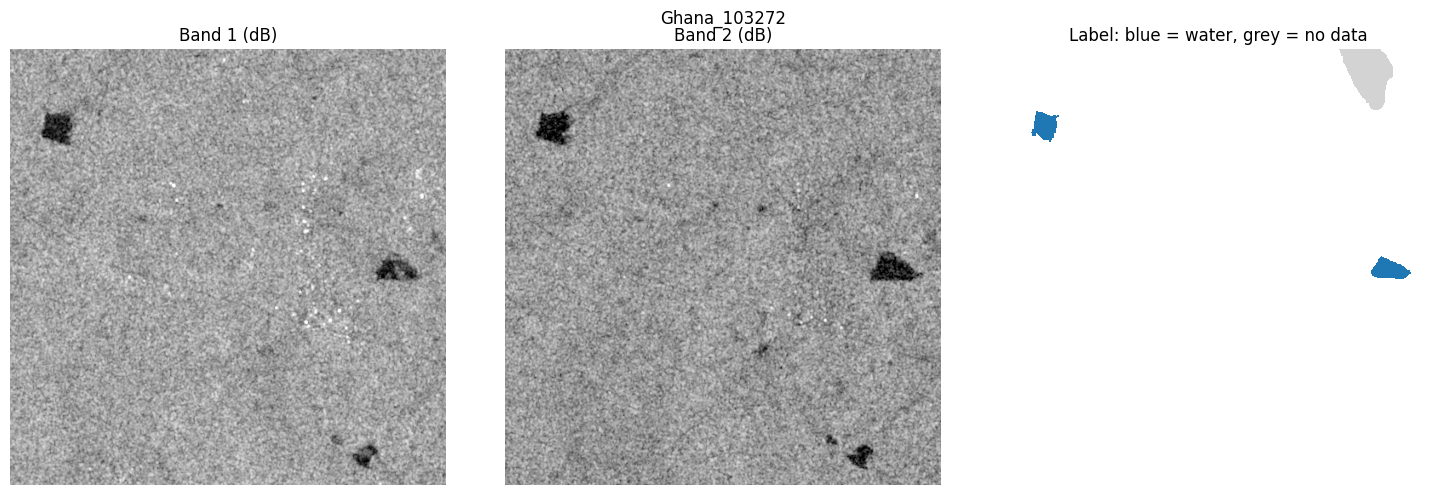

In [6]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(s1[0], cmap='gray', vmin=-25, vmax=0);  ax[0].set_title('Band 1 (dB)')
ax[1].imshow(s1[1], cmap='gray', vmin=-30, vmax=-5); ax[1].set_title('Band 2 (dB)')
label_cmap = ListedColormap(['lightgrey', 'white', 'tab:blue'])   # -1, 0, 1
ax[2].imshow(lab, cmap=label_cmap, vmin=-1, vmax=1, interpolation='nearest')
ax[2].set_title('Label: blue = water, grey = no data')
for a in ax:
    a.axis('off')
plt.suptitle(cid)
plt.tight_layout()
plt.show()

In [7]:
def load_chip(cid):
    """Return (s1, label) for one chip: s1 is (2, 512, 512) float32 [VV, VH] in dB, label is (512, 512) int16."""
    with rasterio.open(f'{DATA_DIR}/S1Hand/{cid}_S1Hand.tif') as src:
        s1 = src.read().astype('float32')
    with rasterio.open(f'{DATA_DIR}/LabelHand/{cid}_LabelHand.tif') as src:
        lab = src.read(1)
    return s1, lab

rows = []
for split, df in splits.items():
    for f in tqdm(df['s1'], desc=split):
        cid = f.replace('_S1Hand.tif', '')
        s1, lab = load_chip(cid)
        nan_px = np.isnan(s1).any(axis=0)              # True where VV or VH is NaN
        rows.append({'split': split, 'chip': cid, 'event': cid.split('_')[0],
                     'water': int((lab == 1).sum()),
                     'land': int((lab == 0).sum()),
                     'nodata': int((lab == -1).sum()),
                     'nan_px': int(nan_px.sum()),
                     'nan_on_labelled_px': int((nan_px & (lab != -1)).sum())})

stats = pd.DataFrame(rows)
summary = stats.groupby('split')[['water', 'land', 'nodata', 'nan_px', 'nan_on_labelled_px']].sum()
summary['water_%'] = (100 * summary['water'] / (summary['water'] + summary['land'])).round(1)
summary['chips_with_no_water'] = stats[stats['water'] == 0].groupby('split').size()
summary

train:   0%|          | 0/252 [00:00<?, ?it/s]

valid:   0%|          | 0/89 [00:00<?, ?it/s]

test:   0%|          | 0/90 [00:00<?, ?it/s]

bolivia:   0%|          | 0/15 [00:00<?, ?it/s]

,water,land,nodata,nan_px,nan_on_labelled_px,water_%,chips_with_no_water
split,,,,,,,
bolivia,454864,2412951,1064345,406204,43381,15.9,NaN
test,2566101,17951266,3075593,560796,73408,12.5,7.0
train,5447035,51856372,8756881,1325136,24150,9.5,33.0
valid,2237605,18057120,3036091,219569,20571,11.0,12.0


In [8]:
by_event = stats.groupby('event').agg(chips=('chip', 'count'),
                                      water=('water', 'sum'), land=('land', 'sum'))
by_event['water_%'] = (100 * by_event['water'] / (by_event['water'] + by_event['land'])).round(1)
by_event.sort_values('water_%', ascending=False)

,chips,water,land,water_%
event,,,,
Mekong,30,1720184,5410998,24.1
Nigeria,18,948331,3094816,23.5
Bolivia,15,454864,2412951,15.9
Spain,30,1016500,6711302,13.2
India,68,1855692,13122901,12.4
Sri-Lanka,42,1175411,8787850,11.8
Paraguay,67,1399139,15279961,8.4
Pakistan,28,403107,4973488,7.5
Somalia,26,349869,5025530,6.5


train:   0%|          | 0/252 [00:00<?, ?it/s]

Sampled water px: 470,506 | not-water px: 4,531,386


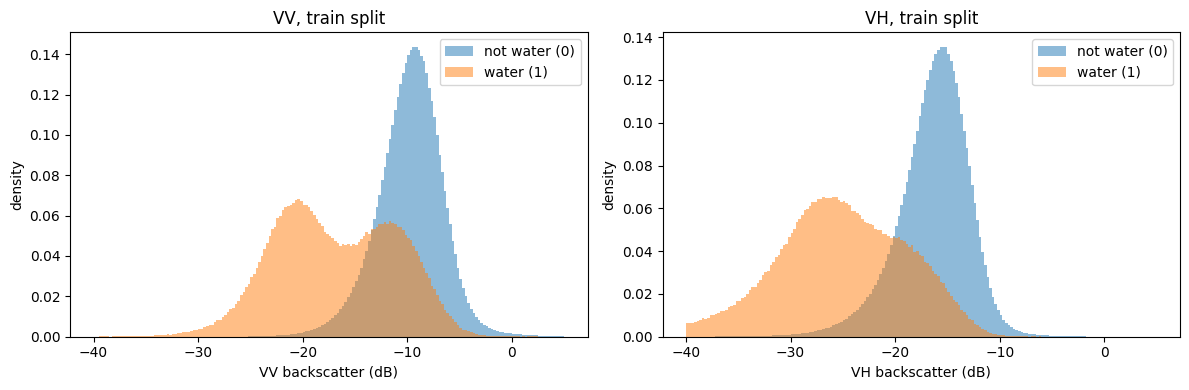

VV: water median -17.2 dB | not-water median -9.6 dB
VH: water median -25.4 dB | not-water median -16.0 dB


In [9]:
rng = np.random.default_rng(0)                # fixed seed so the sample is reproducible
vv_w, vv_l, vh_w, vh_l = [], [], [], []
for f in tqdm(splits['train']['s1'], desc='train'):
    s1, lab = load_chip(f.replace('_S1Hand.tif', ''))
    valid = (lab != -1) & ~np.isnan(s1).any(axis=0)
    idx = np.flatnonzero(valid)
    idx = rng.choice(idx, size=min(20000, idx.size), replace=False)   # sample 20k pixels per chip
    l, vv, vh = lab.ravel()[idx], s1[0].ravel()[idx], s1[1].ravel()[idx]
    vv_w.append(vv[l == 1]); vv_l.append(vv[l == 0])
    vh_w.append(vh[l == 1]); vh_l.append(vh[l == 0])
vv_w, vv_l, vh_w, vh_l = map(np.concatenate, (vv_w, vv_l, vh_w, vh_l))
print(f'Sampled water px: {vv_w.size:,} | not-water px: {vv_l.size:,}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(-40, 5, 181)
for a, w, l, name in [(ax[0], vv_w, vv_l, 'VV'), (ax[1], vh_w, vh_l, 'VH')]:
    a.hist(l, bins=bins, density=True, alpha=0.5, label='not water (0)')
    a.hist(w, bins=bins, density=True, alpha=0.5, label='water (1)')
    a.set_xlabel(f'{name} backscatter (dB)'); a.set_ylabel('density')
    a.set_title(f'{name}, train split'); a.legend()
plt.tight_layout(); plt.show()

for name, w, l in [('VV', vv_w, vv_l), ('VH', vh_w, vh_l)]:
    print(f'{name}: water median {np.median(w):.1f} dB | not-water median {np.median(l):.1f} dB')